# The motor decoder → `decoder_rings_1obj.pdf`, `decoder_rings_2obj.pdf`, `response_error.pdf`

A ring decoder fit to the recorded population, then read out on 1- and 2-object stimuli. The
read-out (`fit_tuning`, `joint_fit`, `decode`, `nearest_max_errors` and the annulus plotting)
is in `decoder_lib.py`; the pool and the population's responses are in `population_lib.py`.

## The pool

* **Selection.** Every neuron passing the shared 2-object modulation criterion of
  `figures/config.py`: 1339 neurons, the same as figure 3's model comparison
  (`population_lib.candidate_units`).
* **Not split-corrected.** The neurons are selected on the same trials the decoder is scored
  on.

**No wedge.** The figure contrasts a 2-object decode against its own *additive null*, not one
sub-population against another.

In [1]:
# ── CONFIG ───────────────────────────────────────────────────────────────────
# The decoder's hyperparameters, and nothing else.

SUBJECTS = ['Perle', 'Elgar']

# ── The population ───────────────────────────────────────────────────────────
# One population, always: every neuron passing the shared 2-object modulation criterion of
# ../../config.py, for that subject. No wedge, no sub-selection — the figure compares the
# decode against its own additive null, not one population against another.
NUM_NEURONS  = 100    # neurons drawn from the pool WITH REPLACEMENT — the decoder's input
                     #   dimension, fixed so runs are comparable whatever the pool holds
N_BOOTSTRAPS = 5     # independent draws, each refit from scratch, pooled in the figure.
                     #   Runtime scales with this.
SEED         = 0     # the draws and the fit's training sample; draw `boot` uses SEED + boot

# ── The population's response model ──────────────────────────────────────────
NUM_REPLICAS     = 64     # rotated copies of every neuron, evenly spaced, each also
                          #   mirrored. Makes the population rotation-equivariant, which is
                          #   what forces the decoder's weights to depend only on
                          #   (phi - preferred direction).
SAMPLE_SIGMA_DEG = 15.0   # width of the circular-Gaussian kernel that reads a response off
                          #   a neuron's own trials at an arbitrary stimulus angle

# ── The decoder's lobe ───────────────────────────────────────────────────────
# A truncated cosine: cos(Delta * pi / 2w) inside |Delta| <= w and exactly 0 outside, so the
# lobe has compact support and a neuron contributes nothing to read-out angles further than
# w from its preferred direction.
LOBE_WIDTH_DEG = 30.0     # the half-width w: where the lobe reaches zero (HWHM is 2w/3).
                          #   One global width; only amplitude and phase are per neuron.

# ── The joint fit ────────────────────────────────────────────────────────────
FIT_N_SAMPLES = 1000   # single-trial 1-object population responses to fit against; the
                       #   trial noise is what makes the amplitudes identifiable
FIT_K_MAX     = 6      # harmonics k = 1 ... K in the objective (k = 0 is excluded: a
                       #   phi-constant cannot move a maximum)
FIT_ITERS     = 3      # alternations of (exact amplitude solve, phase sweep)

# ── The 2-object sweep, and what is measured off it ──────────────────────────
SWEEP_THETA0_DEG     = (3.0, 90.0, 1.5)   # (start, stop, step) of the swept (theta0,
                                          #   -theta0) pairs; both objects contribute a
                                          #   point, filling the [0, 360) angle axis
PEAK_MIN_HEIGHT_FRAC = 0.5   # a decode maximum counts as an object only if it reaches this
                             #   fraction of the way from the decode's floor to its peak
ERROR_BINS_DEG = (80.0, 280.0, 25.0)   # (start, stop, step); stop included. The bins
                                       # repulsion_bias.ipynb uses, which is what makes the
                                       # monkeys' own bias comparable to the decoder's.

# ── The ring panels' example stimuli ─────────────────────────────────────────
RING_SUBJECT         = 'Perle'    # the rings show one subject ...
RING_BOOTSTRAP       = 0          # ... and one of its draws
RING_1OBJ_DEG        = [0, 120, 240]
RING_2OBJ_THETA0_DEG = [45.0, 65, 90.0]    # each drawn as (theta0, -theta0)
# ─────────────────────────────────────────────────────────────────────────────

In [2]:
import functools
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# The repository root (where paths.py lives), found from this notebook's folder.
_root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'paths.py').exists())
sys.path.insert(0, str(_root))
import paths
sys.path.append(str(paths.FIGURES / 'figure_3'))
sys.path.append(str(paths.FIGURES))
import common

import decoder_lib as dl
import population_lib as pl

sys.path.append(str(paths.FIGURES / 'figure_3/motor_decoding'))
import figure_style as fs     # how the figures look

common.set_style()

grid_phi = dl.decode_grid()
n_copies = NUM_REPLICAS * 2
print(f'{len(SUBJECTS)} subjects x {N_BOOTSTRAPS} draws = '
      f'{len(SUBJECTS) * N_BOOTSTRAPS} decoders for the sweep; the ring figure needs 1')

2 subjects x 5 draws = 10 decoders for the sweep; the ring figure needs 1


## 1. The decoder

`build_decoder` draws `NUM_NEURONS` neurons for one (subject, bootstrap) and fits their joint
decoder; `decoder(subject, boot)` is the same thing, memoised. **Nothing is fit by this
cell** — a decoder is built the first time a figure asks for it, and kept.

That is what makes the two figures below independent. The ring figure needs one decoder, so
running it costs a single fit (~8 s); the sweep needs all `len(SUBJECTS) × N_BOOTSTRAPS` of
them and reuses whatever the ring figure already built. Neither re-runs the other, and
re-running either one after it has its decoders is instant.

Each fit prints its report: how much of the target it leaves unexplained, how many amplitudes
came out negative (a neuron given negative weight to cancel another's lobe — the joint fit's
whole point), and how far the phases moved from the 1-object cosine fit they started at.

In [3]:
# The candidate pool and the session trial files do not depend on the draw, so they are read
# once and reused across every bootstrap.
@functools.lru_cache(maxsize=None)
def _pool(subject):
    # The pool: every neuron passing the shared modulation criterion of ../../config.py
    # (1339 neurons). The titration in efficient_coding/ adds a fit-strength cut on top of
    # this, so its pool is a smaller subset.
    return pl.candidate_units(subject)


_SESSIONS = {}          # (subject, session) -> that session's cleaned trials, read once


def _sessions_for(units_df):
    missing = pd.DataFrame([r for _, r in units_df[['subject', 'session']]
                            .drop_duplicates().iterrows()
                            if (r['subject'], r['session']) not in _SESSIONS])
    if len(missing):
        _SESSIONS.update(pl._session_trials(missing))
    return _SESSIONS


def build_decoder(subject, boot=0):
    """Draw one population and fit its decoder. Returns what the read-out needs."""
    pool_df = _pool(subject)
    units_df, counts = pl.sample_units(pool_df, np.arange(len(pool_df)), NUM_NEURONS,
                                       np.random.default_rng(SEED + boot))
    sessions = _sessions_for(units_df)
    units_1obj = pl.load_units_1obj_trials(units_df, session_cache=sessions)
    units_2obj = pl.load_units_2obj_trials(units_df, session_cache=sessions)

    # The per-neuron cosine fit supplies only the phase initialisation; the decoder's
    # amplitudes and phases come from the joint fit below.
    tune = dl.fit_tuning(units_1obj)
    rng = np.random.default_rng(SEED)
    theta_train = rng.uniform(0, 2 * np.pi, FIT_N_SAMPLES)
    R_train = pl.population_sample_1obj(units_1obj, theta_train, NUM_REPLICAS,
                                        SAMPLE_SIGMA_DEG, rng)
    amps, psi, info = dl.joint_fit(
        R_train, theta_train, len(units_df), NUM_REPLICAS, LOBE_WIDTH_DEG,
        psi_init=tune['mu'], k_max=FIT_K_MAX, n_iter=FIT_ITERS)
    mu_eff = pl.replica_preferred_directions(psi, NUM_REPLICAS)
    W = dl.decoder_weights_from_means(mu_eff, grid_phi, width_deg=LOBE_WIDTH_DEG,
                                      amplitudes=np.repeat(amps, n_copies))

    dpsi = np.degrees(np.abs((psi - tune['mu'] + np.pi) % (2 * np.pi) - np.pi))
    print(f'{subject:6s} boot {boot}: {NUM_NEURONS} draws from {len(pool_df)} candidates '
          f'hit {int((counts > 0).sum())} distinct '
          f'({units_df["session"].nunique()} sessions)')
    print(f'         joint fit: unexplained {info["unexplained"][0]:.3f} -> '
          f'{info["unexplained"][-1]:.3f} | {int((amps < 0).sum())}/{len(amps)} amplitudes '
          f'negative | phase moved {np.median(dpsi):.0f}° (median)')
    return dict(units_1obj=units_1obj, units_2obj=units_2obj,
                decode=lambda r: dl.decode(W, r))


def response_1obj(dec, theta):
    return pl.population_response_1obj(dec['units_1obj'], theta, NUM_REPLICAS,
                                       SAMPLE_SIGMA_DEG)[0]


def response_2obj(dec, t0, t1):
    return pl.population_response_2obj(dec['units_2obj'], t0, t1, NUM_REPLICAS,
                                       SAMPLE_SIGMA_DEG)[0]


def response_2obj_additive(dec, t0, t1):
    # What a strictly ADDITIVE code would give for this pair, from this population's own
    # 1-object responses: [f(t0) + f(t1)]/2. Same neurons, same decoder — only the code is
    # different.
    return dl.additive_2obj_response(dec['units_1obj'], t0, t1, NUM_REPLICAS,
                                     SAMPLE_SIGMA_DEG)[0]


def _hyperparameters():
    """Everything a fitted decoder depends on — the cache key below."""
    return (NUM_NEURONS, SEED, NUM_REPLICAS, SAMPLE_SIGMA_DEG, LOBE_WIDTH_DEG,
            FIT_N_SAMPLES, FIT_K_MAX, FIT_ITERS)


_DECODERS = {}


def decoder(subject, boot):
    """One fitted decoder, built on first use and kept for the rest of the session.

    This is what lets the two figures below be run independently: the ring cell fits the one
    decoder it draws (~8 s), and the sweep cell fits the rest, reusing that one rather than
    redoing it. Re-running either cell afterwards costs nothing.

    The key includes the CONFIG values, so editing a hyperparameter and re-running the CONFIG
    cell invalidates what was fit under the old ones instead of silently reusing it.
    """
    key = (subject, boot, _hyperparameters())
    if key not in _DECODERS:
        _DECODERS[key] = build_decoder(subject, boot)
    return _DECODERS[key]


print('definitions only — nothing is fit until a figure below asks for a decoder')

definitions only — nothing is fit until a figure below asks for a decoder


## 2. The ring heatmaps  ·  one decoder

The decode over the whole ring for a few example stimuli, from `RING_SUBJECT`'s draw
`RING_BOOTSTRAP`. **This cell fits that one decoder and nothing else**, so the example figure
can be redrawn — different stimuli, different subject, different peak criterion — without
touching the bootstrapped sweep below. The green crosses are the decode's local maxima,
subject to `PEAK_MIN_HEIGHT_FRAC`.

The rings of a row are drawn on a **single** axis at x = 0, `fs.RING_SPACING`,
2·`fs.RING_SPACING`, … rather than in one subplot each. With subplots the gap could not
shrink below the blank margin every ring keeps inside its own axes, and cutting that margin
clipped the stimulus dots at the panel edge; on one long axis the spacing is just a distance
(in ring radii, so 2.0 = touching) and nothing is ever clipped between panels.

Perle  boot 0: 100 draws from 998 candidates hit 97 distinct (10 sessions)
         joint fit: unexplained 0.129 -> 0.066 | 47/100 amplitudes negative | phase moved 24° (median)
saved decoder_rings_1obj.pdf  (3 panels, [1, 1, 1] maxima)


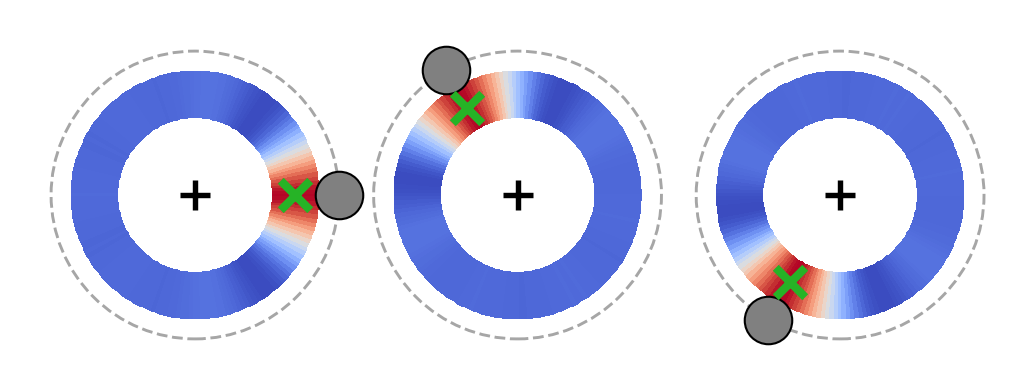

saved decoder_rings_2obj.pdf  (3 panels, [2, 2, 2] maxima)


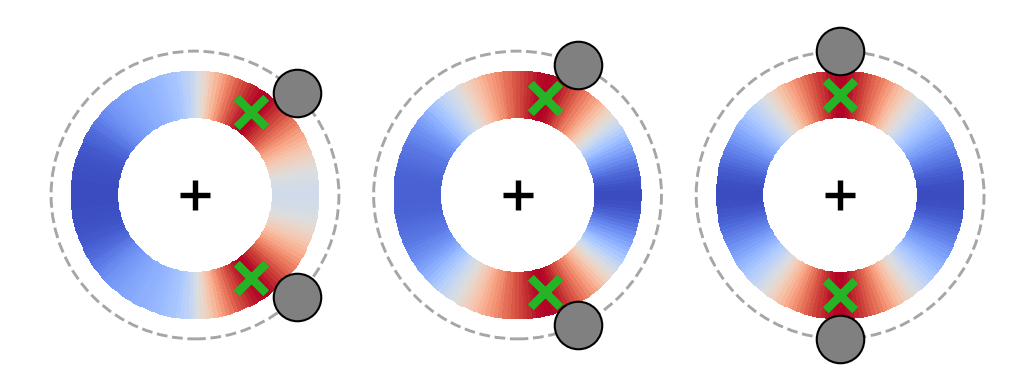

In [4]:
dec = decoder(RING_SUBJECT, RING_BOOTSTRAP)   # fits this one draw, and only this one
panels = {
    '1obj': [([np.radians(d)], dec['decode'](response_1obj(dec, np.radians(d))))
             for d in RING_1OBJ_DEG],
    '2obj': [([np.radians(d), np.radians(-d) % (2 * np.pi)],
              dec['decode'](response_2obj(dec, np.radians(d), np.radians(-d) % (2 * np.pi))))
             for d in RING_2OBJ_THETA0_DEG],
}

for tag, out_path in (('1obj', fs.OUTPUT_RINGS_1OBJ), ('2obj', fs.OUTPUT_RINGS_2OBJ)):
    # All the rings share ONE axis, at x = 0, RING_SPACING, 2·RING_SPACING, … — so the gap
    # between them is a plain distance in ring radii and nothing sits at a subplot edge to
    # be cut off. The axis is framed once, after the loop.
    fig, ax = plt.subplots(figsize=fs.FIGSIZE_RINGS)
    centers = dl.annulus_row_centers(len(panels[tag]), fs.RING_SPACING)
    n_peaks = []
    for center, (marks, vals) in zip(centers, panels[tag]):
        peaks = dl.local_maxima(grid_phi, vals, min_height_frac=PEAK_MIN_HEIGHT_FRAC)
        n_peaks.append(len(peaks))
        dl.plot_annulus(ax, grid_phi, vals, center=center, cmap=fs.RING_CMAP,
                        mark=marks, mark_color=fs.STIM_MARK_COLOR,
                        mark_size=fs.STIM_MARK_SIZE, stim_ring_color=fs.STIM_RING_COLOR,
                        stim_ring_lw=fs.STIM_RING_LW, stim_ring_alpha=fs.STIM_RING_ALPHA,
                        peaks=peaks, peak_color=tuple(fs.PEAK_MARK_RGB),
                        peak_marker=fs.PEAK_MARK_MARKER, peak_size=fs.PEAK_MARK_SIZE,
                        peak_edge=fs.PEAK_MARK_EDGE)
        # The fixation cross, at the center of the ring — as in figure_2/psth's stimulus
        # panels. It is inside the annulus' hole, so nothing is drawn over it.
        ax.plot([center], [0.0], marker='+', color='k', markersize=fs.FIX_MARK_SIZE,
                markeredgewidth=fs.FIX_MARK_LINEWIDTH, zorder=4)
    dl.annulus_row_limits(ax, len(panels[tag]), fs.RING_SPACING, margin=fs.RING_MARGIN)
    fig.savefig(out_path, bbox_inches='tight', pad_inches=0.01)
    print(f'saved {out_path}  ({len(panels[tag])} panels, {n_peaks} maxima)')
    plt.show()

## 3. The 2-object sweep  ·  every decoder

Every `(θ₀, −θ₀)` pair in `SWEEP_THETA0_DEG`, decoded, with the nearest decode maximum to
each object giving that object's signed error. Both objects contribute a point, so the sweep
fills the whole inter-object-angle axis.

**This is the slow cell**: it fits whichever of the `len(SUBJECTS) × N_BOOTSTRAPS` decoders
the ring cell has not already built, then sweeps each — a couple of minutes from cold.

In [ ]:
sweep_conds = [(t0, (-t0) % (2 * np.pi))
               for t0 in np.radians(np.arange(SWEEP_THETA0_DEG[0],
                                              SWEEP_THETA0_DEG[1] + 1e-9,
                                              SWEEP_THETA0_DEG[2]))]

# One decode per draw per swept condition, and the additive null alongside it,
# [f(t0) + f(t1)]/2 from this population's OWN 1-object responses, through the SAME decoder:
# it is additive by construction, so whatever bias it shows is the decoder's own blur. The draws are pooled here: they resample which
# neurons the decoder gets, and the figure shows the pooled cloud.
points = {}
for subject in SUBJECTS:
    for tag, resp in [('real', response_2obj), ('additive', response_2obj_additive)]:
        rel, err = [], []
        for boot in range(N_BOOTSTRAPS):
            d = decoder(subject, boot)
            D = [d['decode'](resp(d, t0, t1)) for t0, t1 in sweep_conds]
            r, e = dl.nearest_max_errors(grid_phi, sweep_conds, D,
                                         min_height_frac=PEAK_MIN_HEIGHT_FRAC)
            rel.append(r), err.append(e)
        points[(subject, tag)] = (np.concatenate(rel), np.concatenate(err))
        print(f'{subject:6s} {tag:8s}: {len(points[(subject, tag)][0])} points '
              f'({len(sweep_conds)} conditions x 2 objects x {N_BOOTSTRAPS} draws)')

Perle  boot 1: 100 draws from 998 candidates hit 98 distinct (9 sessions)
         joint fit: unexplained 0.127 -> 0.061 | 50/100 amplitudes negative | phase moved 23° (median)
Perle  boot 2: 100 draws from 998 candidates hit 95 distinct (9 sessions)
         joint fit: unexplained 0.127 -> 0.064 | 52/100 amplitudes negative | phase moved 16° (median)
Perle  boot 3: 100 draws from 998 candidates hit 97 distinct (10 sessions)
         joint fit: unexplained 0.137 -> 0.075 | 49/100 amplitudes negative | phase moved 20° (median)


## 4. Response error vs. inter-object angle

**One figure**, one subplot per monkey, carrying two series and no others:

| series | what it is |
|---|---|
| rainbow dots | the population's decoded response error, binned by inter-object angle, in the bin colours of `figure_1/repulsion_bias` |
| gray dots | the **additive null**: the same neurons and the same decoder on a code that is additive by construction, so whatever bias it shows is the decoder's own blur rather than the population's |

The figure is the **gap between them**. Neither is worth much alone: the decoder has a finite
lobe width and its response estimate is kernel-smoothed, so some repulsion is manufactured by
the read-out, and the null is exactly how much.

Error bars are the 95% CI of each bin mean. The y limits come from the real series alone, so
the null running off the panel at the closest separations — where it merges the two objects — cannot
flatten the curve.

Nothing above is re-run by this cell, so it is the one to iterate the figure design on.

saved response_error.pdf


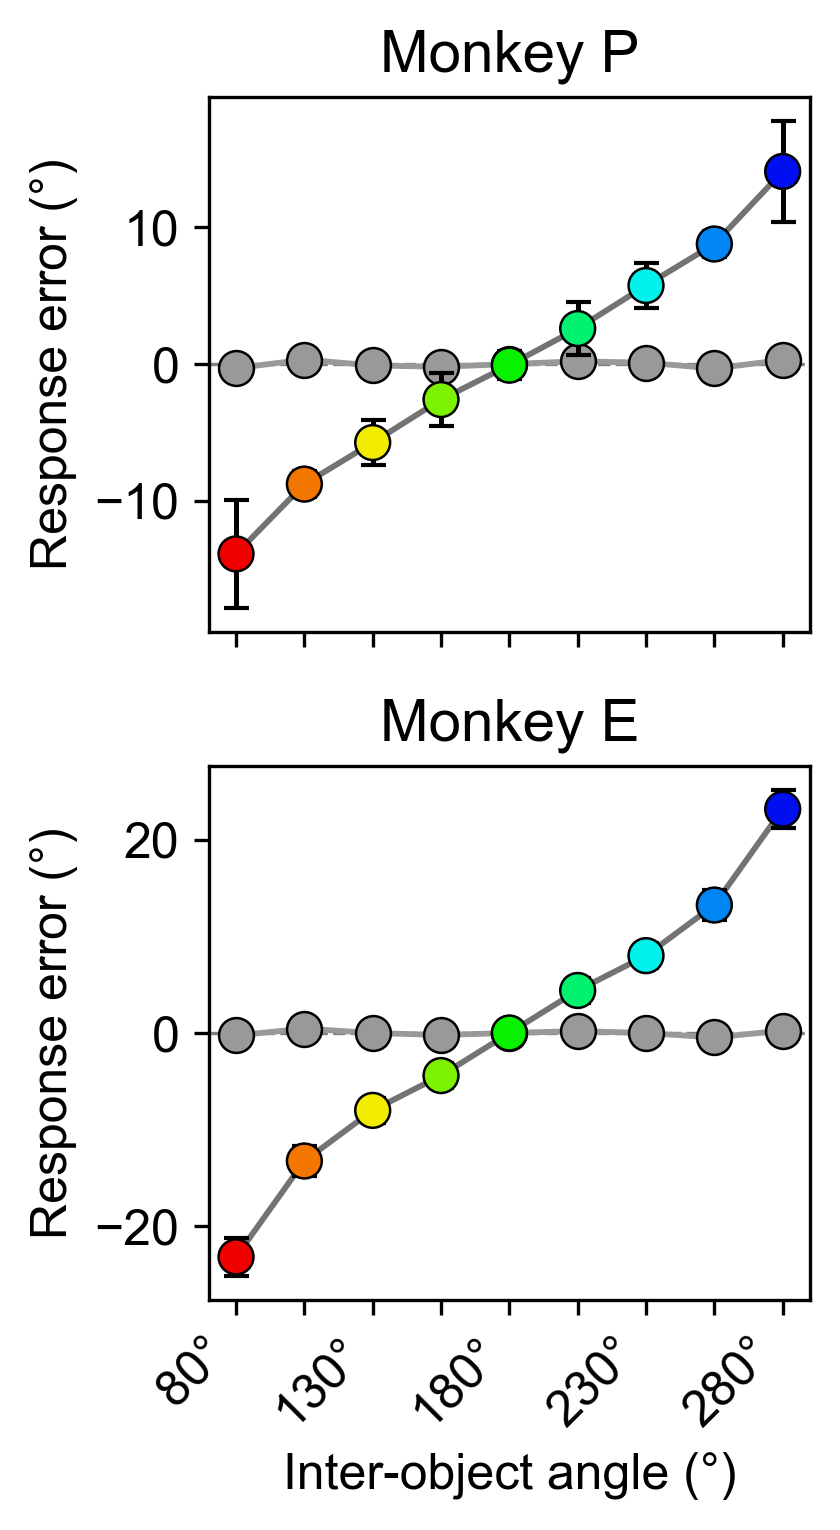

In [ ]:
# This cell re-runs in a second: `points` and the fitted decoders are already in the kernel
# from the cells above and nothing here touches them. Change a value, re-run this cell alone.
FIGSIZE = (2.9, 5.2)            # (width, height) in inches; one subject per row

bins = np.arange(ERROR_BINS_DEG[0], ERROR_BINS_DEG[1] + 1e-9, ERROR_BINS_DEG[2])
labelled = {round(v, 6) for v in fs.ERROR_BIN_LABELS_DEG}
bin_colors = dl.bin_colors(len(bins))
Z95 = 1.96      # error bars are the normal 95% CI of each bin MEAN. With hundreds of points
                # per bin the t correction is under a percent, and a bootstrap would only
                # matter if a bin were badly skewed.

# One subject per row, sharing the x axis.
fig, axes = plt.subplots(len(SUBJECTS), 1, figsize=FIGSIZE, squeeze=False, sharex=True)
axes = axes.ravel()
extent = []          # y range of the REAL series only, per subplot
for ax, subject in zip(axes, SUBJECTS):
    ax.axhline(0, color='k', lw=0.8, alpha=0.5, ls='--', zorder=1)

    # The additive null first, so it sits BEHIND the real response: the same neurons and the
    # same decoder on a code that is additive by construction, so whatever bias it shows is
    # the decoder's own blur. Bin means only — a second cloud in one panel is not a figure.
    c_a, m_a, _, _ = dl.bin_error_summary(*points[(subject, 'additive')], bins)
    ax.plot(c_a, m_a, ls=fs.ERROR_LINESTYLE, color=fs.ADDITIVE_COLOR, lw=1.4, zorder=2.3)
    ax.scatter(c_a, m_a, marker=fs.ERROR_MARKER, s=70, color=fs.ADDITIVE_COLOR,
               edgecolors='k', linewidths=0.6, zorder=2.5)

    # The real response on top, in figure_1/repulsion_bias's per-bin colours.
    rel, err = points[(subject, 'real')]
    c, m, sd, n = dl.bin_error_summary(rel, err, bins)
    ci = Z95 * sd / np.sqrt(np.maximum(n, 1))
    ax.plot(c, m, ls=fs.ERROR_LINESTYLE, color='0.45', lw=1.4, zorder=3.3)
    ax.errorbar(c, m, yerr=ci, fmt='none', ecolor='k', elinewidth=1.2, capsize=3, zorder=3.4)
    ax.scatter(c, m, marker=fs.ERROR_MARKER, s=70, edgecolors='k', linewidths=0.6, zorder=3.5,
               c=[bin_colors[int(np.argmin(np.abs(bins - v)))] for v in c])
    extent.append(((m - ci).min(), (m + ci).max()))

    ax.set_xticks(bins)
    ax.set_xticklabels([f'{v:.0f}°' if round(v, 6) in labelled else '' for v in bins],
                       rotation=45, ha='right')
    ax.set_title(pl.SUBJECT_TITLE.get(subject, subject))

# Each panel's y range follows its own REAL series alone. The additive null never sets it:
# where it merges the two objects it lands tens of degrees out, which would flatten the curve
# this figure exists to show.
_pad = plt.rcParams['axes.ymargin']
for ax, (lo, hi) in zip(axes, extent):
    ax.set_ylim(lo - _pad * (hi - lo), hi + _pad * (hi - lo))

axes[-1].set_xlabel('Inter-object angle (°)')
for ax in axes[:-1]:
    ax.set_xlabel('')
for ax in axes:                          # every panel: they are separate y axes and each
    ax.set_ylabel('Response error (°)')  # wants naming
fig.tight_layout()
fig.subplots_adjust(hspace=fs.ERROR_HSPACE)  # after tight_layout, which would override it
fig.savefig(fs.OUTPUT_ERROR, bbox_inches='tight', pad_inches=0.01)
print(f'saved {fs.OUTPUT_ERROR}')
plt.show()